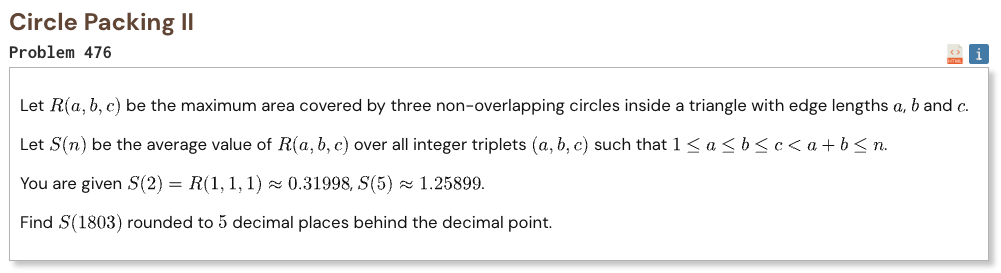

## Initial approach

- sort the triangle sides so the smallest angle is opposite the shortest side
- first place the incircle because it must be part of the best three circle packing
- circles placed repeatedly inside one corner have radii that shrink by a fixed ratio
- the largest extra circle comes from the smallest angle of the triangle
- the third circle is either the first circle from the second smallest angle or the next circle from the smallest angle
- use Heron's formula and half angle formulas to calculate these radii directly from the side lengths
- loop over every valid integer triangle and average its maximum covered area
- use numba to compile the large triple loop because there are many triangles for n = 1803

In [1]:
%%time

import math
from numba import njit

N = 1803

@njit
def triangle_circle_area(a, b, c):
    p = a + b + c

    x = p - 2 * a
    y = p - 2 * b
    z = p - 2 * c

    r2 = x * y * z / (4.0 * p)

    sin_half_a = math.sqrt(
        y * z / (4.0 * b * c)
    )

    sin_half_b = math.sqrt(
        x * z / (4.0 * a * c)
    )

    q_a = (
        (1.0 - sin_half_a)
        / (1.0 + sin_half_a)
    )

    q_b = (
        (1.0 - sin_half_b)
        / (1.0 + sin_half_b)
    )

    second = q_a * q_a
    third = max(
        q_b * q_b,
        second * second
    )

    return math.pi * r2 * (
        1.0 + second + third
    )

@njit
def solve(n):
    total = 0.0
    count = 0

    for a in range(1, n // 2 + 1):
        for b in range(a, n - a + 1):
            c_max = a + b - 1

            for c in range(b, c_max + 1):
                total += triangle_circle_area(
                    a, b, c
                )
                count += 1

    return total / count

result = solve(N)

print("Result:", f"{result:.5f}")

Result: 110242.87794
CPU times: user 1.49 s, sys: 139 ms, total: 1.62 s
Wall time: 3.1 s
